Importing libraries, functions and data

In [ ]:
import sys
sys.path.append(r"C:\Users\mikey\Desktop\Gait+non-linear ananlysis\Gait+non-linear ananlysis\gait_functions") #add the folders for the gait and non-linear functions
sys.path.append(r"C:\Users\mikey\Desktop\Gait+non-linear ananlysis\Gait+non-linear ananlysis\non-linear functions")

#import warnings
#warnings.filterwarnings("ignore", category=DeprecationWarning) 

%pip install ssqueezepy
%pip install C:\Users\mikey\Documents\GitHub\forest #Need to make a clone the repository and paste the path here 

import numpy as np
import pandas as pd
from scipy.signal import resample
import csv
import matplotlib.pyplot as plt


from walking import find_walking # this function returns cadence form which step count and walking periods are found
from hs_to_detection import get_hs_to_wavelet # function to detect heal strike and toe off from the walking data
from hs_to_detection import  gait_parameters  # function to calculate gait parameters from heal strike and toe off



filename = r"C:\Users\mikey\Desktop\Gait+non-linear ananlysis\Gait+non-linear ananlysis\50step.csv" #"C:\Users\Ayush Dubey\Downloads\2024-05-0500.27.21.csv" #csv file of acclerometer in units of 'g'
accleration = pd.read_csv(filename)
R_acc = accleration['TgF'] - 1 #resultant acceleration adjusted with gravity
fs = 500 # sampling frequency of sensor
vm = np.array(R_acc) #converting to numpy array
#print(np.size(vm))

Note: you may need to restart the kernel to use updated packages.


ERROR: Invalid requirement: 'C:\\Users\\mikey\\Documents\\GitHub\\forest': Expected end or semicolon (after name and no valid version specifier)
    C:\Users\mikey\Documents\GitHub\forest
     ^
Hint: It looks like a path. File 'C:\Users\mikey\Documents\GitHub\forest' does not exist.


Note: you may need to restart the kernel to use updated packages.


ModuleNotFoundError: No module named 'walking'

Parameters for find_walking and get_hs_to_wavelet function

In [64]:
# Resample the signal to 10 hz find_walking needs signal sampled at 10 hz
fs_walking = 10 # sampling rate required by find_walking function
num_samples = int(np.size(vm)*fs_walking/fs)
vm_resample = resample(vm, num_samples)

# For the function to work properly it needs the number of samples to be a multiple of frequency(10hz)
# the function arranges the signal into matrix with each column containing 10 samples ie data for 1 second
num_elements_to_use = (vm_resample.size // fs_walking) * fs_walking
vm_bout = vm_resample[:num_elements_to_use]
#print(num_samples)

# parameters for find walking function
min_amp = 0.3 # amplitude threshold (in g )
T = 3 # minimum walking duration (in seconds)
delta = 20 #maximum difference between consecutive peaks (in multiplication of 0.05Hz)
alpha = 1.6 #maximum ratio between dominant peak below and within step frequency range
beta = 2.5 # maximum ratio between dominant peak above and within step frequency range
step_freq = (1.4,2.3) #step frequency range (in Hz or steps per second)

# heal strike toe off detection
fs_HS_TO = 100 #sampling frequency needed by the function
turning = 0 
plot_figure = 1 # 1 for plotting the figure
save_fig_name = "Test" 

Cad is cadence for each 1 second of signal  

In [65]:
cad = find_walking(vm_bout, 10, min_amp,step_freq, alpha, beta, T,delta)

In [66]:
wi = np.where(cad > 0, 1, 0) # cad[i] >0 indicates walking in ith second
wi_resampled = np.repeat(wi,fs_HS_TO) # streching the wi vector to match with sampling rate needed in get_hs_to_wavelet function

In [67]:
'''
with open('cad.csv', 'w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    writer.writerow(cad)

with open('wi_resampled100.csv', 'w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    writer.writerow(wi_resampled)
'''

"\nwith open('cad.csv', 'w', newline='') as csvfile:\n    writer = csv.writer(csvfile)\n    writer.writerow(cad)\n\nwith open('wi_resampled100.csv', 'w', newline='') as csvfile:\n    writer = csv.writer(csvfile)\n    writer.writerow(wi_resampled)\n"

Walking indices for 100 hz data used for heal strike and toe off 

In [68]:
# Find indices where wi changes from 0 to 1 and from 1 to 0
change_indices = np.where(np.diff(wi_resampled) != 0)[0]

# Preallocate walking array based on the maximum potential size
walking = np.zeros((len(change_indices) // 2, 2), dtype=int) # each row denotes the start and end index of walking in 100hz sampling rate signal

# Iterate through change indices and fill the walking array directly
for i in range(0, len(change_indices), 2):
    x0 = change_indices[i]
    x1 = change_indices[i+1]
    walking[i//2, 0] = x0 + 1 # +1 is done to get the exact location of index where walking started np.diff function gave the index before the walking started
    walking[i//2, 1] = x1 # walk ends

# Display the results
print(change_indices)
print(walking) 

[2499 4199 4499 6199]
[[2500 4199]
 [4500 6199]]


In [69]:
az = accleration['gFz'] # acceleration in the anterior posterior directtion
num_samples = int(len(az) * fs_HS_TO / fs)  # Calculate the number of samples in the resampled signal
# Resample the signal
resampled_az = resample(az, num_samples)

Create a dataframe which will contain the walking period index and gait parameters(in seconds)

In [70]:
df = pd.DataFrame(columns=['walking_index','steps','time', 'start_index', 'end_index', 'foot1_hs','foot2_hs','foot1_to','foot2_to','gait_cycle_time_foot1','gait_cycle_time_foot2','dst1_foot1','dst1_foot2','dst2_foot1','dst2_foot2',
         'sst1_foot1','sst1_foot2','sst2_foot1','sst2_foot2','stance_time1_foot1','stance_time1_foot2','stance_time2_foot1','stance_time2_foot2',
         'swing_time1_foot1','swing_time1_foot2','swing_time2_foot1','swing_time2_foot2'])


for i in range(len(walking)):
    walk_start = walking[i,0]
    walk_end= walking[i,1]
    walk = resampled_az[walk_start:walk_end]

    # Get heal strike and toe off
    hs_selected_idx, to_selected_idx, invalid_hs_idx = get_hs_to_wavelet(walk, fs_HS_TO, turning, plot_figure, save_fig_name, wavelet_type_straight="gaus1", wavelet_type_turning="gaus1")
    # converted to float and dividing by 100 to get results in units of second
    hs_selected_idx = (hs_selected_idx.astype(float))/100
    to_selected_idx = (to_selected_idx.astype(float))/100
    # get gait parameters
    df = gait_parameters(hs_selected_idx,to_selected_idx,df,i,walk_start,walk_end,cad,fs,fs_HS_TO)

This is a straight walking dataset, will gaus1
Dominant frequency: 1.471454, with power: -13.014832
Plotting
This is a straight walking dataset, will gaus1
Dominant frequency: 1.471454, with power: -12.430739
Plotting


Save the data frame

In [71]:
df.to_csv('dfccc.csv', index=False)

Non Linear Analysis of Walking

In [72]:
from ami_stergio import AMI_Stergiou
from fnn import FNN
from ent_Ap import Ent_Ap
from ent_symbolic import Ent_Symbolic
from entMSPlus import Ent_MS_Plus
from entPermu import Ent_Permu
from lye_R import LyE_R
from lye_W import LyE_W
from rqa import RQA
from ent_Samp import Ent_Samp

In [73]:
# identify walking 
import numpy as np
import pandas as pd
from scipy.signal import resample
import csv
import matplotlib.pyplot as plt


from walking import find_walking # this function returns cadence form which step count and walking periods are found
from hs_to_detection import get_hs_to_wavelet # function to detect heal strike and toe off from the walking data
from hs_to_detection import  gait_parameters  # function to calculate gait parameters from heal strike and toe off

#filename = r"C:\Users\Ayush Dubey\Desktop\50step.csv" #"C:\Users\Ayush Dubey\Downloads\2024-05-0500.27.21.csv" #csv file of acclerometer in units of 'g'
accleration = pd.read_csv(filename)
R_acc = accleration['TgF'] - 1 #resultant acceleration adjusted with gravity
fs = 500 # sampling frequency of sensor
vm = np.array(R_acc) #converting to numpy array
#print(np.size(vm))

In [74]:
# Resample the signal to 10 hz find_walking needs signal sampled at 10 hz
fs_walking = 10 # sampling rate required by find_walking function
num_samples = int(np.size(vm)*fs_walking/fs)
vm_resample = resample(vm, num_samples)

# For the function to work properly it needs the number of samples to be a multiple of frequency(10hz)
# the function arranges the signal into matrix with each column containing 10 samples ie data for 1 second
num_elements_to_use = (vm_resample.size // fs_walking) * fs_walking
vm_bout = vm_resample[:num_elements_to_use]
#print(num_samples)

# parameters for find walking function
min_amp = 0.3 # amplitude threshold (in g )
T = 3 # minimum walking duration (in seconds)
delta = 20 #maximum difference between consecutive peaks (in multiplication of 0.05Hz)
alpha = 1.6 #maximum ratio between dominant peak below and within step frequency range
beta = 2.5 # maximum ratio between dominant peak above and within step frequency range
step_freq = (1.4,2.3) #step frequency range (in Hz or steps per second)

fs_HS_TO = 100 #sampling frequency used for gait parameters and non linear analysis


cad = find_walking(vm_bout, 10, min_amp,step_freq, alpha, beta, T,delta)

In [75]:
wi = np.where(cad > 0, 1, 0) # cad[i] >0 indicates walking in ith second
wi_resampled = np.repeat(wi,fs_HS_TO) # streching the wi vector to match with sampling rate needed in get_hs_to_wavelet function

In [76]:
# Find indices where wi changes from 0 to 1 and from 1 to 0
change_indices = np.where(np.diff(wi_resampled) != 0)[0]

# Preallocate walking array based on the maximum potential size
walking = np.zeros((len(change_indices) // 2, 2), dtype=int) # each row denotes the start and end index of walking in 100hz sampling rate signal

# Iterate through change indices and fill the walking array directly
for i in range(0, len(change_indices), 2):
    x0 = change_indices[i]
    x1 = change_indices[i+1]
    walking[i//2, 0] = x0 + 1 # +1 is done to get the exact location of index where walking started np.diff function gave the index before the walking started
    walking[i//2, 1] = x1 # walk ends

# Display the results
#print(change_indices)
print(walking) 

[[2500 4199]
 [4500 6199]]


In [77]:
res_acc = R_acc+1 # acceleration in the anterior posterior directtion
num_samples = int(len(res_acc) * fs_HS_TO / fs)  # Calculate the number of samples in the resampled signal
# Resample the signal
resampled_res_acc = resample(res_acc, num_samples)

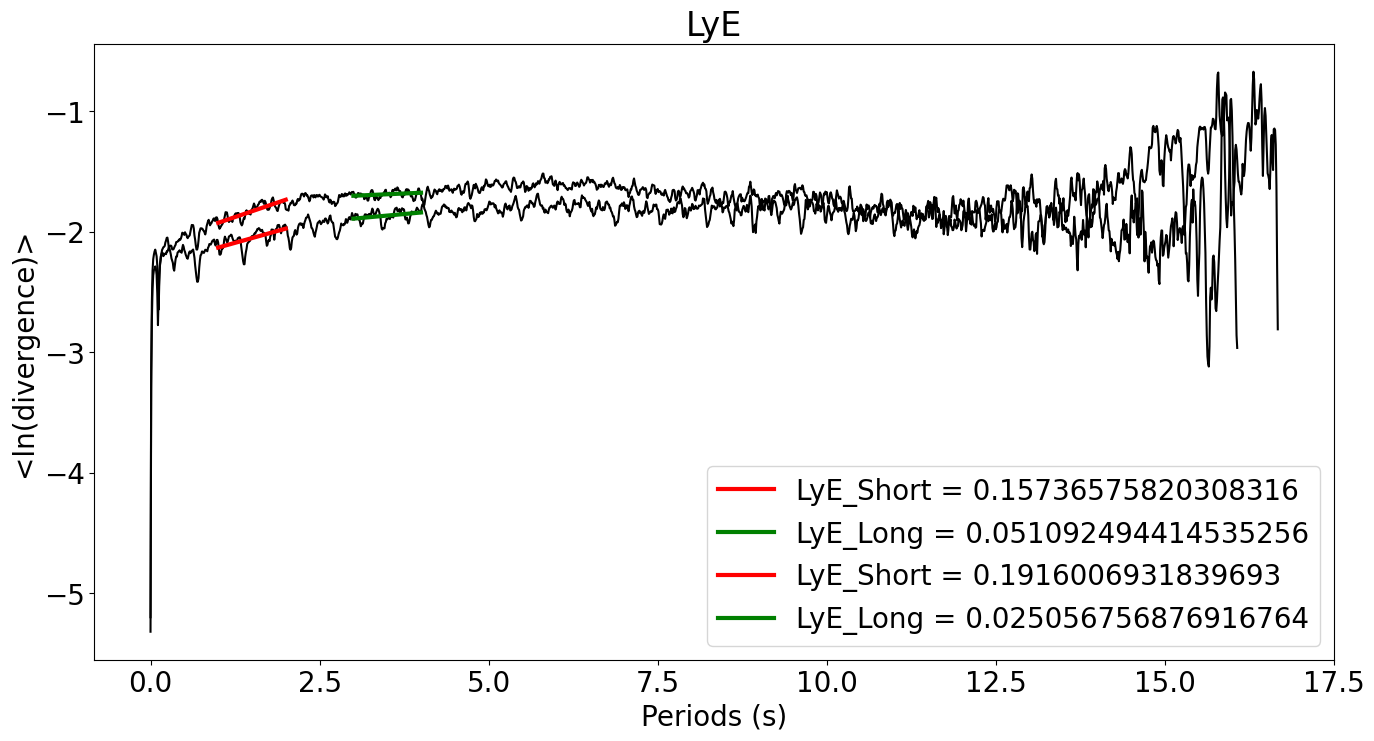

In [78]:
df2 = pd.DataFrame(columns=['walking_index','start_index', 'end_index','delay','dimension','Ap_en','Samp_en','Sym_en',
                            'Permu_en','LyEl_R','LyEs_R','Lye_W','REC','DET','MeanL','MaxL',
                            'EntrL','LAM','MeanV','MaxV','EntrV','EntrW','RCMSE','CMSE','MSE','MSE_SCALE1','MSE_SCALE2'])

for i in range(len(walking)):
    walk_start = walking[i,0]
    walk_end= walking[i,1]
    data = resampled_res_acc[walk_start:walk_end]
    #Calculate delay from Stergiou
    tau, V_ami = AMI_Stergiou(data,35)
    delay = int(tau[0][0])
    #Calculate dimensions from fnn
    # Parameters for fnn function
    MaxDim = 30
    Rtol = 15
    Atol = 2
    speed = 0
    ans = FNN(data, delay, MaxDim, Rtol, Atol, speed)    
    dim = ans[1]  #dimension
    # Approximate entropy
    r = 0.2 #tolerance
    AE = Ent_Ap(data, dim, r)
    # Sample Entropy
    m = 2 # - m is generally recommendation as 2
    #  - R is generally recommendation as 0.2
    Samp_Ent = Ent_Samp(data, m, r)
    #Symbolic Entropy
    L = 2 #assuming
    Sym_En = Ent_Symbolic(data, L)
    # Permutaion Entropy
    '''
    (permEnt, hist) = Ent_Permu20180320(data, m, tau)
    inputs -  data: 1-D array of data being analyzed
              m: embedding dimension (order of permutation entropy) 
              tau: time delay
    outputs - permuEnt: value calculated using a log base of 2
              hist: number of occurences for each permutation order
'''
    [permEnt_value,hist_value] = Ent_Permu(data, m, delay)
    #LyE_Rosenstein
    name = "test"
    slope = [1,2,3,4]
    MeanPeriod = 1
    Plot = True
    (LyEl,LyEs,out) = LyE_R(data,name,fs_HS_TO,delay,m,slope, MeanPeriod, Plot)
    #largest lyapunov exponent
    evolve = 2 # assuming
    [out,lye] = LyE_W(data, fs_HS_TO, delay, dim, evolve)
    # RQA
    TYPE = 'RQA'
    ZSCORE = 1
    NORM = 'NON'
    LINELENGTH = 1
    SETVALUE = 1
    SETPARA = 'radius'
    PLOTOPTION = 0
    column = "1"
    nargout =1
    rqa_RESULTS = RQA(data, TYPE ,dim,delay,ZSCORE,NORM,LINELENGTH,SETPARA,SETVALUE,PLOTOPTION, column, nargout)
    REC=rqa_RESULTS[0]['REC']
    DET=rqa_RESULTS[0]['DET']
    MeanL= rqa_RESULTS[0]['MeanL']
    MaxL= rqa_RESULTS[0]['MaxL']
    EntrL= rqa_RESULTS[0]['EntrL']
    LAM= rqa_RESULTS[0]['LAM']
    MeanV= rqa_RESULTS[0]['MeanL']
    MaxV= rqa_RESULTS[0]['MaxV']
    EntrV=rqa_RESULTS[0]['EntrV']
    EntrW=rqa_RESULTS[0]['EntrW']

    tau = 20
    r = 0.2
    m=2

    result =  Ent_MS_Plus(data,tau, m, r )

    RCMSE =result[0]
    CMSE = result[1]
    MSE = result[2] 
    # Initialize a list to store rows
    rows = []
    # change MSE to an array of 3 columns 
    # Iterate through the array and build rows
    for item in MSE:
        if isinstance(item, tuple):
            rows.append(item)  # Append the tuple as is
        else:
            rows.append((item, np.nan, np.nan))  # Convert non-tuple items to (item, NaN, NaN)

    # Convert the list of rows to a NumPy array
    MSE = np.array(rows)
    # chnage the data type to float 
    RCMSE = RCMSE.astype(float)
    CMSE = CMSE.astype(float)

    # Pad the single float value variable with nan values
    max_len = MSE.shape[0]

    lists = [i+1,walk_start,walk_end,delay,dim,AE,Samp_Ent,Sym_En,permEnt_value,LyEl,LyEs,lye,REC,DET,MeanL,MaxL,EntrL,LAM,MeanV,MaxV,EntrV,EntrW]
    padded_lists = []

    # Pad each variable
    for value in lists:
        # Convert scalar to array and pad
        value_array = np.array([value])
        value_array = value_array.astype(float)
        padded_array = np.pad(value_array, (0, max_len - len(value_array)), mode='constant', constant_values=np.nan)
        padded_lists.append(padded_array)

    # Convert list of padded arrays to a 2D NumPy array
    padded_lists = np.vstack(padded_lists)
    padded_lists = np.transpose(padded_lists)

    new_row = pd.DataFrame({'walking_index':padded_lists[:,0],'start_index':padded_lists[:,1], 'end_index':padded_lists[:,2],'delay':padded_lists[:,3],'dimension':padded_lists[:,4],'Ap_en':padded_lists[:,5],'Samp_en':padded_lists[:,6],'Sym_en':padded_lists[:,7],
                            'Permu_en':padded_lists[:,8],'LyEl_R':padded_lists[:,9],'LyEs_R':padded_lists[:,10],'Lye_W':padded_lists[:,11],'REC':padded_lists[:,12],'DET':padded_lists[:,13],'MeanL':padded_lists[:,14],'MaxL':padded_lists[:,15],
                            'EntrL':padded_lists[:,16],'LAM':padded_lists[:,17],'MeanV':padded_lists[:,18],'MaxV':padded_lists[:,19],'EntrV':padded_lists[:,20],'EntrW':padded_lists[:,21],'RCMSE':RCMSE,'CMSE':CMSE,'MSE':MSE[:,0],'MSE_SCALE1':MSE[:,1],'MSE_SCALE2':MSE[:,2]})  

    df2 = pd.concat([df2, new_row], ignore_index=True)



In [79]:
df2.to_csv('df222222.csv', index=False)